
--- MENU ---
1 - Thay doi bien do
2 - Thay doi bac hai
3 - Thay doi tan so co ban F0
4 - Thay doi pha
5 - Ve do thi va phat am thanh
0 - Thoat
Lua chon khong hop le!

--- MENU ---
1 - Thay doi bien do
2 - Thay doi bac hai
3 - Thay doi tan so co ban F0
4 - Thay doi pha
5 - Ve do thi va phat am thanh
0 - Thoat


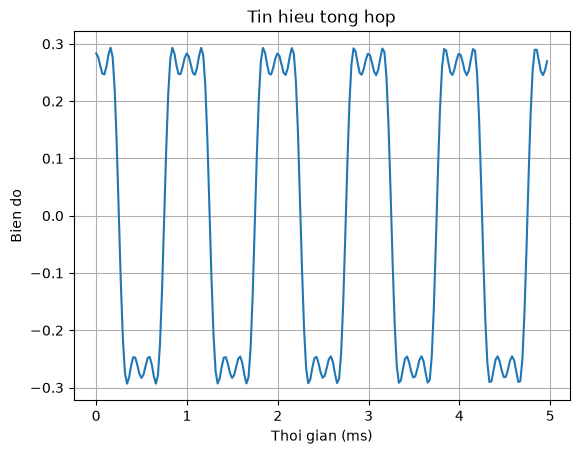


--- MENU ---
1 - Thay doi bien do
2 - Thay doi bac hai
3 - Thay doi tan so co ban F0
4 - Thay doi pha
5 - Ve do thi va phat am thanh
0 - Thoat


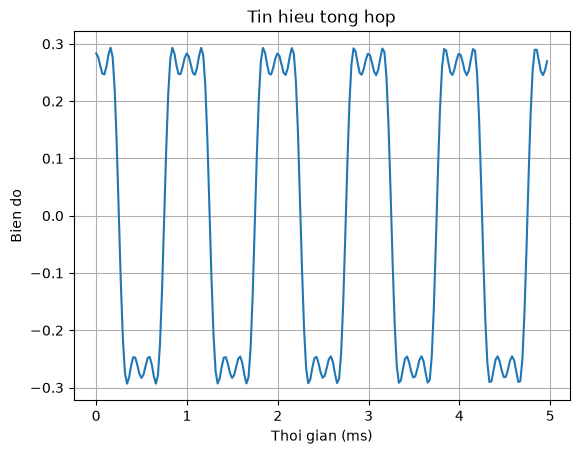


--- MENU ---
1 - Thay doi bien do
2 - Thay doi bac hai
3 - Thay doi tan so co ban F0
4 - Thay doi pha
5 - Ve do thi va phat am thanh
0 - Thoat


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd

F0 = 1000       # Tan so co ban (Hz)
fs = 44100      # So mau trong 1 giay
T = 1           # Thoi gian phat am thanh (giay)

A = [5, 5, 5]  # Bien do cua 3 song
k = [1, 3, 10]           # Bac hai cua 3 song
pha = [0, 0, 0]         # Pha (do)

while True:
    print('\n--- MENU ---')
    print('1 - Thay doi bien do')
    print('2 - Thay doi bac hai')
    print('3 - Thay doi tan so co ban F0')
    print('4 - Thay doi pha')
    print('5 - Ve do thi va phat am thanh')
    print('0 - Thoat')

    chon = input('Chon chuc nang: ')

    if chon == '0':
        break

    if chon in ('1', '2', '4'):
        i = int(input('Chon song so (1, 2 hoac 3): ')) - 1

        if i not in (0, 1, 2):
            print('Chi co 3 song!')
            continue

        if chon == '1':
            A[i] = float(input('Nhap bien do moi: '))

        elif chon == '2':
            bac = int(input('Nhap bac hai moi (>= 1): '))
            if bac < 1 or bac * F0 >= fs / 2:
                print('Bac hai khong hop le hoac tan so qua cao!')
                continue
            k[i] = bac

        else:
            pha[i] = float(input('Nhap pha moi (do): '))

    elif chon == '3':
        f = float(input('Nhap F0 moi (Hz): '))
        if f <= 0 or max(k) * f >= fs / 2:
            print('F0 phai duong va cac song phai duoi fs/2!')
            continue
        F0 = f

    elif chon != '5':
        print('Lua chon khong hop le!')
        continue

    # Tao tin hieu
    t = np.arange(0, T, 1/fs) #
    x = np.zeros(len(t))

    for i in range(3):
        x += A[i] * np.cos(
            2*np.pi*k[i]*F0*t + np.deg2rad(pha[i])
        )

    # Ve 5 ms dau tien
    n = int(0.005 * fs)

    plt.plot(t[:n] * 1000, x[:n])
    plt.xlabel('Thoi gian (ms)')
    plt.ylabel('Bien do')
    plt.title('Tin hieu tong hop')
    plt.grid()
    plt.show()

    # Phat am thanh
    peak = np.max(np.abs(x))

    if peak > 1.0:
        x_safe = x / peak
    else:
        x_safe = x

    am_thanh = x_safe * 0.3

    # 4. Phát
    sd.play(am_thanh, fs)
    sd.wait()
